<a href="https://colab.research.google.com/github/zefilho1985/minera-o/blob/main/lp_stacking_corrigido_v3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predição de proficiência em Língua Portuguesa

Coloque a planilha `LP.dados.turma(01) (3) (4)(3).xlsx` na mesma pasta de execução do notebook e execute as células em ordem. A Etapa 02 também aceita o nome original `LP.dados.turma(01).xlsx`.

- **Modelo principal (Algoritmo 1):** PREPROC (PolynomialFeatures grau 2 → PCA ≥ 95% → StandardScaler → SelectKBest k = 20) → Stacking com RF, XGBoost, CatBoost e SVR → meta-modelo Ridge (`passthrough=True`).
- **Treino:** as 515 turmas, sem remoção de outliers. As etapas 06B e 06C mostram que a remoção não muda de forma significativa as correlações nem a distribuição da proficiência.
- **Seleção:** o alpha do Ridge é escolhido só com as turmas de treino (validação cruzada, Etapa 21B). As 221 turmas de teste são usadas apenas na avaliação final (Etapa 21C em diante).
- **Comparação (Etapa 22):** todos os algoritmos no mesmo PREPROC e no mesmo protocolo.
- **Auditoria (Etapa 26):** verificações automáticas de vazamento, reprodutibilidade e consistência dos números.
- A divisão é aleatória por turma, com escolas compartilhadas entre treino e teste.

In [1]:
%pip install numpy==2.4.6 pandas==2.2.3 scipy==1.16.3 matplotlib==3.10.0 seaborn==0.13.2 scikit-learn==1.6.1 xgboost==3.4.1 openpyxl==3.1.5 catboost==1.2.10 statsmodels==0.15.0 shap==0.54.1


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.6 MB/s  0:00:12


In [2]:
#etapa02
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from scipy.stats import kstest
# 1. Carregar os dados
from pathlib import Path

PLANILHA = Path("LP.dados.turma(01) (3) (4)(3).xlsx")
if not PLANILHA.is_file():
    PLANILHA = Path("LP.dados.turma(01).xlsx")
df = pd.read_excel(PLANILHA)

# 2. Limpar vírgulas, converter pra float, arredondar e finalmente pra int
for col in ['INICIAL', 'INTERMEDIARIO', 'FINAL', 'PROFICIENCIA']:
    df[col] = (
        df[col]
          .astype(str)                          # garante que é string
          .str.replace(',', '', regex=False)     # remove vírgulas (se houver)
          .astype(float)                         # converte pra float
          .round(0)                              # arredonda pra inteiro mais próximo
          .astype(int)                           # converte pra int
    )


In [3]:
#etapa03
from sklearn.model_selection import train_test_split
# 3. Definir X e y
X = df[['INICIAL', 'INTERMEDIARIO', 'FINAL']]
display(X)
y = df['PROFICIENCIA']
display(y)

# 4. Split 70/30
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42
)

print(f'Treino:  X_train={X_train.shape}, y_train={y_train.shape}')
print(f'Teste:   X_test={X_test.shape}, y_test={y_test.shape}')


,INICIAL,INTERMEDIARIO,FINAL
0,56,60,63
1,47,51,52
2,64,70,71
3,57,56,55
4,41,58,60
...,...,...,...
731,58,67,66
732,70,68,73
733,72,70,78
734,73,73,77


,PROFICIENCIA
0,258
1,211
2,271
3,250
4,230
...,...
731,260
732,274
733,280
734,275


Treino:  X_train=(515, 3), y_train=(515,)
Teste:   X_test=(221, 3), y_test=(221,)


,INICIAL,INTERMEDIARIO,FINAL,PROFICIENCIA
265,64,67,69,257
537,58,74,71,258
260,52,50,72,240
137,68,65,69,258
479,61,66,68,250
...,...,...,...,...
71,47,25,66,244
106,68,69,76,266
270,67,68,80,262
435,61,62,72,237


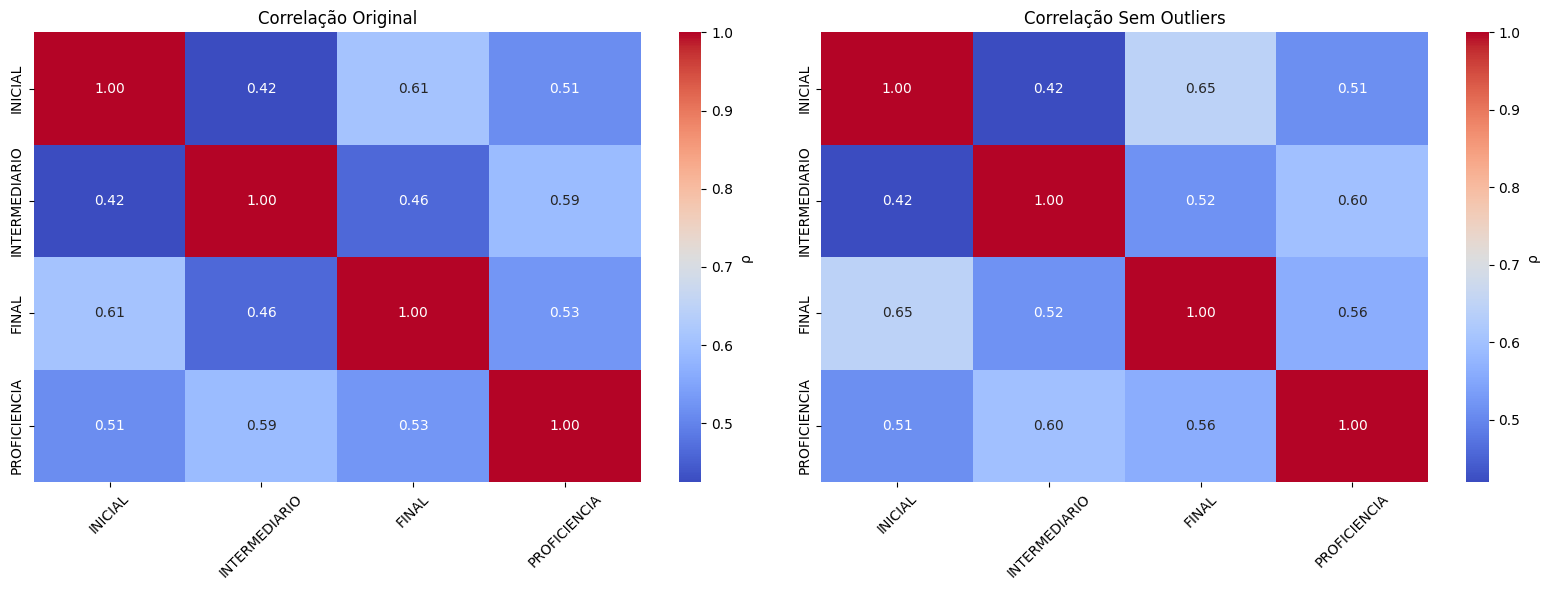

In [4]:
#ETAPA06
# 1. Reunir X_train e y_train
df_train = pd.concat([X_train, y_train], axis=1)
display(df_train)

# 2. Análise Exploratória e Tratamento de Outliers
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# 2.1 Matriz de correlação original
corr_orig = df_train.corr()

# 2.2 Remoção de outliers pelo método IQR
Q1 = df_train.quantile(0.25)
Q3 = df_train.quantile(0.75)
IQR = Q3 - Q1
mask = ~((df_train < (Q1 - 1.5 * IQR)) | (df_train > (Q3 + 1.5 * IQR))).any(axis=1)
df_clean = df_train[mask]

# 2.3 Matriz de correlação sem outliers
corr_clean = df_clean.corr()

# 2.4 Plotagem
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_orig,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[0]
)
axes[0].set_title('Correlação Original')
axes[0].tick_params(axis='x', rotation=45)

sns.heatmap(
    corr_clean,
    annot=True, fmt='.2f',
    cmap='coolwarm',
    cbar_kws={'label': 'ρ'},
    ax=axes[1]
)
axes[1].set_title('Correlação Sem Outliers')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


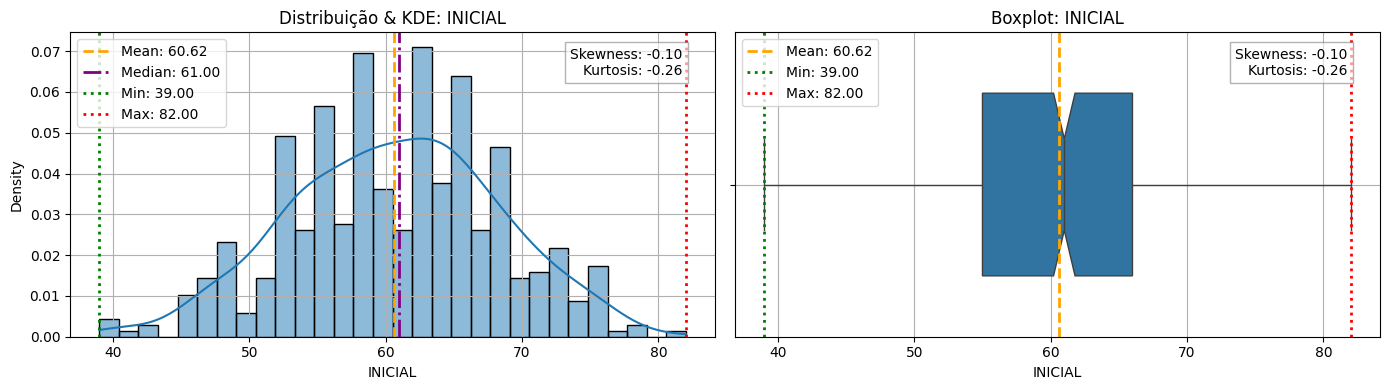

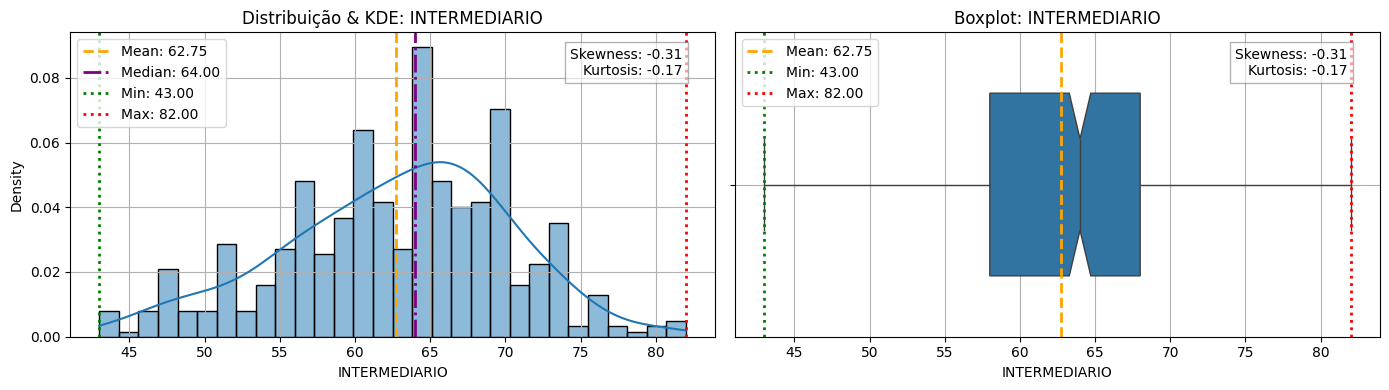

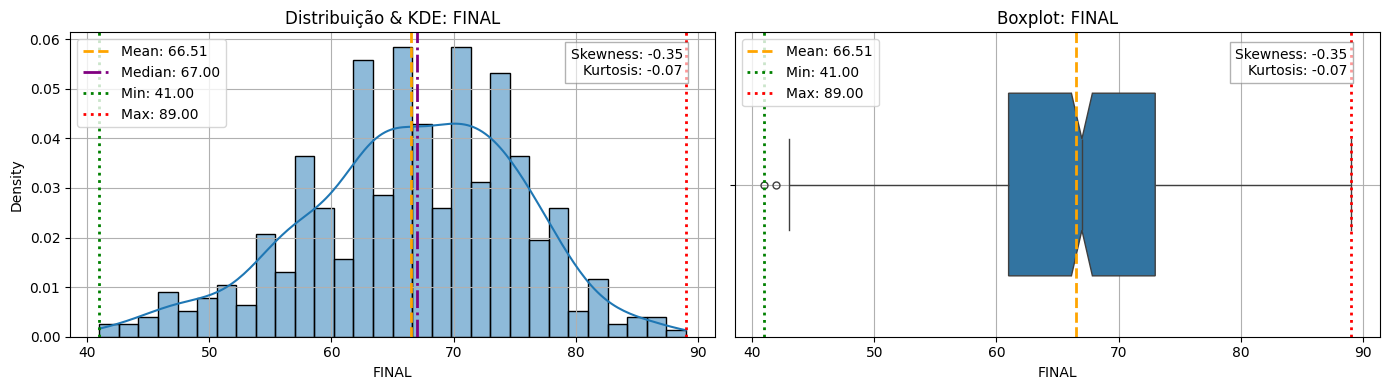

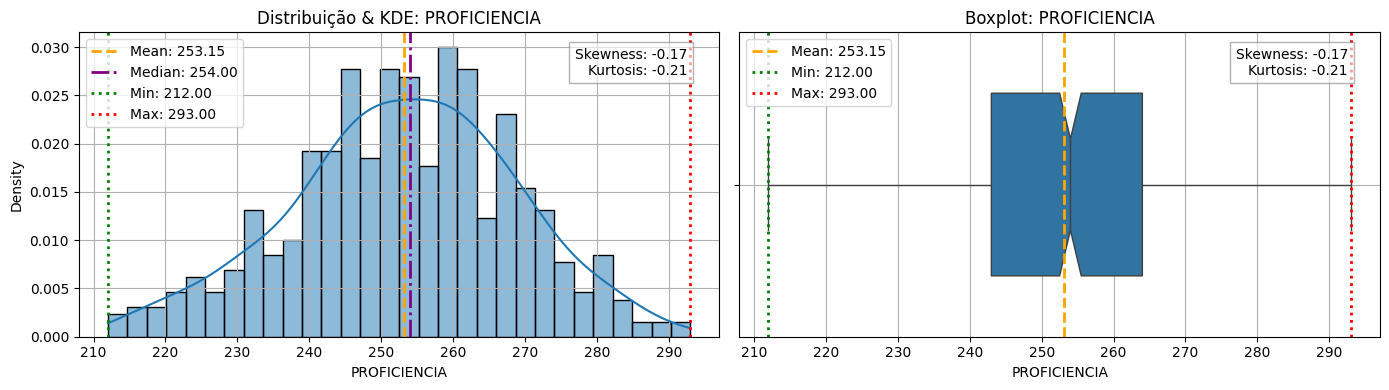

In [5]:
#ETAPA07
# 3. Estatísticas Descritivas aprimoradas
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt



for col in df_clean.columns:
    vals = df_clean[col]
    mean    = vals.mean()
    median  = vals.median()
    min_val = vals.min()
    max_val = vals.max()
    skew    = vals.skew()
    kurt    = vals.kurtosis()

    fig, (ax_hist, ax_box) = plt.subplots(1, 2, figsize=(14, 4))

    # --- Histograma + KDE ---
    sns.histplot(vals, bins=30, kde=True, stat='density', ax=ax_hist)
    ax_hist.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_hist.axvline(median, color='purple', linestyle='-.', linewidth=2, label=f'Median: {median:.2f}')
    ax_hist.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_hist.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_hist.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_hist.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_hist.set_title(f'Distribuição & KDE: {col}')
    ax_hist.legend()
    ax_hist.grid(True)

    # --- Boxplot notch ---
    sns.boxplot(x=vals, notch=True, width=0.6, fliersize=5, ax=ax_box)
    ax_box.axvline(mean,   color='orange', linestyle='--', linewidth=2, label=f'Mean: {mean:.2f}')
    ax_box.axvline(min_val, color='green', linestyle=':', linewidth=2, label=f'Min: {min_val:.2f}')
    ax_box.axvline(max_val, color='red',   linestyle=':', linewidth=2, label=f'Max: {max_val:.2f}')
    ax_box.text(
        0.95, 0.95,
        f'Skewness: {skew:.2f}\nKurtosis: {kurt:.2f}',
        transform=ax_box.transAxes, ha='right', va='top',
        bbox=dict(facecolor='white', alpha=0.6, edgecolor='gray')
    )
    ax_box.set_title(f'Boxplot: {col}')
    ax_box.legend()
    ax_box.grid(True)

    plt.tight_layout()
    plt.show()


n original = 515 | n sem outliers = 481 | bootstrap: 2000 reamostragens


,r original,r sem outliers,Diferença,IC 95% Zou,Zou: significativa?,IC 95% bootstrap,p (bootstrap),Bootstrap: significativa?
Par,,,,,,,,
INICIAL × INTERMEDIARIO,0.425,0.420,-0.005,[-0.108; 0.097],não,[-0.060; 0.063],0.995,não
INICIAL × FINAL,0.608,0.645,0.038,[-0.038; 0.113],não,[-0.024; 0.079],0.254,não
INICIAL × PROFICIENCIA,0.514,0.513,-0.002,[-0.094; 0.090],não,[-0.058; 0.054],0.882,não
INTERMEDIARIO × FINAL,0.462,0.517,0.055,[-0.040; 0.149],não,[-0.010; 0.127],0.097,não
INTERMEDIARIO × PROFICIENCIA,0.593,0.598,0.005,[-0.076; 0.085],não,[-0.039; 0.058],0.668,não
FINAL × PROFICIENCIA,0.526,0.562,0.035,[-0.052; 0.123],não,[-0.036; 0.100],0.391,não


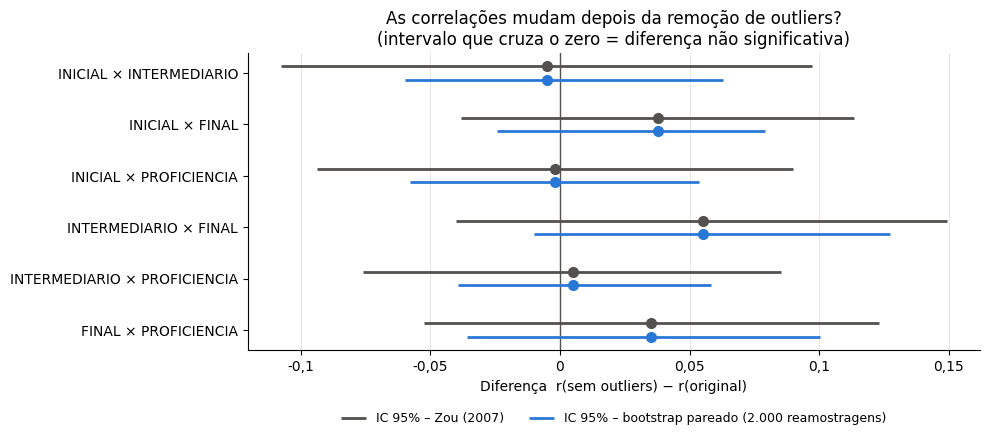

In [6]:
#ETAPA06B — Item 39 (Prof. João): o aumento das correlações depois do IQR é estatisticamente significativo?
# Método de Zou (2007) + bootstrap pareado. Usa df_train e df_clean criados na ETAPA06.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

def ic_fisher(r, n, nivel=0.95):
    """Intervalo de confiança do r de Pearson pela transformação z de Fisher."""
    z, ep = np.arctanh(r), 1 / np.sqrt(n - 3)
    q = stats.norm.ppf(1 - (1 - nivel) / 2)
    return np.tanh(z - q * ep), np.tanh(z + q * ep)

def zou_2007(r1, n1, r2, n2, nivel=0.95):
    """IC 95% para (r2 − r1) — Zou (2007), Psychological Methods 12(4), 399–413."""
    l1, u1 = ic_fisher(r1, n1, nivel)
    l2, u2 = ic_fisher(r2, n2, nivel)
    d = r2 - r1
    return d - np.sqrt((r2 - l2) ** 2 + (u1 - r1) ** 2), d + np.sqrt((u2 - r2) ** 2 + (r1 - l1) ** 2)

def remover_outliers_iqr(d):
    """Mesmo critério da ETAPA06: remove a turma se qualquer coluna estiver fora de [Q1 − 1,5·IQR; Q3 + 1,5·IQR]."""
    Q1, Q3 = d.quantile(0.25), d.quantile(0.75)
    IQR = Q3 - Q1
    fora = ((d < (Q1 - 1.5 * IQR)) | (d > (Q3 + 1.5 * IQR))).any(axis=1)
    return d[~fora.values]

variaveis = list(df_train.columns)
pares = [(a, b) for i, a in enumerate(variaveis) for b in variaveis[i + 1:]]

# Bootstrap pareado: sorteia 515 turmas com reposição, aplica o IQR na reamostra e mede a diferença
B, SEED = 2000, 42
rng = np.random.default_rng(SEED)
dif_boot = np.empty((B, len(pares)))
for i in range(B):
    amostra = df_train.iloc[rng.integers(0, len(df_train), len(df_train))]
    limpa = remover_outliers_iqr(amostra)
    dif_boot[i] = [limpa[a].corr(limpa[b]) - amostra[a].corr(amostra[b]) for a, b in pares]

linhas = []
for k, (a, b) in enumerate(pares):
    r1, r2 = df_train[a].corr(df_train[b]), df_clean[a].corr(df_clean[b])
    zi, zs = zou_2007(r1, len(df_train), r2, len(df_clean))
    bi, bs = np.percentile(dif_boot[:, k], [2.5, 97.5])
    p_boot = min(1.0, 2 * min((dif_boot[:, k] <= 0).mean(), (dif_boot[:, k] >= 0).mean()))
    linhas.append({'Par': f'{a} × {b}',
                   'r original': round(r1, 3), 'r sem outliers': round(r2, 3), 'Diferença': round(r2 - r1, 3),
                   'IC 95% Zou': f'[{zi:.3f}; {zs:.3f}]',
                   'Zou: significativa?': 'sim' if (zi > 0 or zs < 0) else 'não',
                   'IC 95% bootstrap': f'[{bi:.3f}; {bs:.3f}]', 'p (bootstrap)': round(p_boot, 3),
                   'Bootstrap: significativa?': 'sim' if (bi > 0 or bs < 0) else 'não',
                   '_zi': zi, '_zs': zs, '_bi': bi, '_bs': bs})
tab_zou = pd.DataFrame(linhas).set_index('Par')
print(f'n original = {len(df_train)} | n sem outliers = {len(df_clean)} | bootstrap: {B} reamostragens')
display(tab_zou.drop(columns=['_zi', '_zs', '_bi', '_bs']))

# Figura: diferença entre as correlações com os dois intervalos de confiança
CINZA, AZUL = '#52514e', '#2a78d6'
fig, ax = plt.subplots(figsize=(10, 4.6))
ypos = np.arange(len(tab_zou))[::-1]
ax.axvline(0, color=CINZA, lw=1)
ax.hlines(ypos + 0.13, tab_zou['_zi'], tab_zou['_zs'], color=CINZA, lw=2, label='IC 95% – Zou (2007)')
ax.hlines(ypos - 0.13, tab_zou['_bi'], tab_zou['_bs'], color=AZUL, lw=2,
          label='IC 95% – bootstrap pareado (2.000 reamostragens)')
ax.plot(tab_zou['Diferença'], ypos + 0.13, 'o', color=CINZA, ms=7)
ax.plot(tab_zou['Diferença'], ypos - 0.13, 'o', color=AZUL, ms=7)
ax.set_yticks(ypos)
ax.set_yticklabels(tab_zou.index)
ax.set_xlabel('Diferença  r(sem outliers) − r(original)')
ax.set_title('As correlações mudam depois da remoção de outliers?\n(intervalo que cruza o zero = diferença não significativa)')
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:g}'.replace('.', ',')))
ax.grid(axis='x', color='#e6e6e3')
ax.set_axisbelow(True)
for lado in ['top', 'right']:
    ax.spines[lado].set_visible(False)
ax.legend(frameon=False, loc='upper center', bbox_to_anchor=(0.5, -0.17), ncol=2, fontsize=9)
plt.tight_layout()
plt.show()

In [7]:
# ETAPA 06C — Itens 38 e 40 (Prof. João): significância das correlações e testes de média e mediana
# (a) p-valor de cada correlação de Pearson, antes e depois do IQR;
# (b) a proficiência muda depois da remoção de outliers? (Welch, Mann-Whitney, mediana de Mood, Levene, Kolmogorov-Smirnov)
from scipy import stats

def tabela_p(d):
    v = list(d.columns)
    return pd.DataFrame([{'Par': f'{a} × {b}', 'r': d[a].corr(d[b]), 'p-valor': stats.pearsonr(d[a], d[b])[1]}
                         for i, a in enumerate(v) for b in v[i + 1:]]).set_index('Par')
tab_p = pd.concat({f'Original (n = {len(df_train)})': tabela_p(df_train),
                   f'Sem outliers (n = {len(df_clean)})': tabela_p(df_clean)}, axis=1)
print('(a) Correlações de Pearson e p-valores')
display(tab_p.style.format('{:.3f}').format('{:.2e}', subset=[c for c in tab_p.columns if c[1] == 'p-valor']))

p0, p1 = df_train['PROFICIENCIA'], df_clean['PROFICIENCIA']
desc = pd.DataFrame({'Original': p0.describe(), 'Sem outliers (IQR)': p1.describe()}).T
desc['assimetria'] = [p0.skew(), p1.skew()]; desc['curtose'] = [p0.kurtosis(), p1.kurtosis()]
print('(b) Proficiência antes e depois da remoção de outliers')
display(desc.round(2))
testes_dist = pd.DataFrame([
    ('Médias', 't de Welch', stats.ttest_ind(p0, p1, equal_var=False).pvalue),
    ('Medianas', 'Mediana de Mood', stats.median_test(p0, p1)[1]),
    ('Distribuição (postos)', 'Mann-Whitney U', stats.mannwhitneyu(p0, p1).pvalue),
    ('Variâncias', 'Levene', stats.levene(p0, p1).pvalue),
    ('Distribuição completa', 'Kolmogorov-Smirnov', stats.ks_2samp(p0, p1).pvalue)],
    columns=['O que compara', 'Teste', 'p-valor'])
testes_dist['Diferença significativa (α = 0,05)?'] = np.where(testes_dist['p-valor'] < .05, 'sim', 'não')
display(testes_dist.round(4))
print('Decisão: como nem as correlações (06B) nem a distribuição da proficiência (06C) mudam de forma significativa, '
      'os modelos são treinados com as 515 turmas.')

(a) Correlações de Pearson e p-valores


(b) Proficiência antes e depois da remoção de outliers


,count,mean,std,min,25%,50%,75%,max,assimetria,curtose
Original,515.0,252.77,16.83,203.0,243.0,253.0,264.0,309.0,-0.11,0.26
Sem outliers (IQR),481.0,253.15,15.48,212.0,243.0,254.0,264.0,293.0,-0.17,-0.21


,O que compara,Teste,p-valor,"Diferença significativa (α = 0,05)?"
0,Médias,t de Welch,0.7088,não
1,Medianas,Mediana de Mood,0.7998,não
2,Distribuição (postos),Mann-Whitney U,0.7073,não
3,Variâncias,Levene,0.1860,não
4,Distribuição completa,Kolmogorov-Smirnov,1.0000,não


Decisão: como nem as correlações (06B) nem a distribuição da proficiência (06C) mudam de forma significativa, os modelos são treinados com as 515 turmas.


In [8]:
# ETAPA 21A — Arquitetura do Stacking (Algoritmo 1)
# PREPROC → Stacking (Random Forest, XGBoost, CatBoost, SVR) → meta-modelo Ridge com passthrough
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostRegressor
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor, StackingRegressor
from sklearn.feature_selection import SelectKBest, f_regression
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import KFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

SEED = 42
ENTRADAS = ['INICIAL', 'INTERMEDIARIO', 'FINAL']
assert X_train.index.intersection(X_test.index).empty
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

def criar_preproc():
    # PREPROC ← PolyFeatures(grau 2, sem viés) → PCA(≥ 95%) → StandardScaler → SelectKBest(f_regression, k = 20)
    # com 3 entradas, o PCA mantém 3 componentes e o SelectKBest (k = 20 > 3) mantém todas (aviso esperado)
    return Pipeline([
        ('poly', PolynomialFeatures(degree=2, include_bias=False)),
        ('pca', PCA(n_components=0.95, random_state=SEED)),
        ('scaler', StandardScaler()),
        ('kbest', SelectKBest(f_regression, k=20)),
    ])

def criar_bases():
    return [
        ('Random Forest', RandomForestRegressor(n_estimators=300, max_depth=3, min_samples_leaf=10, max_features=0.67,
                                                random_state=SEED, n_jobs=1)),
        ('XGBoost', XGBRegressor(n_estimators=200, max_depth=3, learning_rate=0.01, subsample=0.7, colsample_bytree=1.0,
                                 reg_alpha=0, reg_lambda=10, min_child_weight=5, objective='reg:squarederror',
                                 random_state=SEED, n_jobs=1)),
        ('CatBoost', CatBoostRegressor(iterations=500, depth=3, learning_rate=0.02, l2_leaf_reg=30, subsample=0.8, rsm=0.8,
                                       random_state=SEED, verbose=0, thread_count=1, allow_writing_files=False)),
        ('SVR', SVR(kernel='rbf', C=20, epsilon=2)),
    ]

def criar_stacking(bases=None, alpha=10.0):
    return Pipeline([
        ('pre', criar_preproc()),
        ('stack', StackingRegressor(estimators=bases or criar_bases(), final_estimator=Ridge(alpha=alpha),
                                    passthrough=True, n_jobs=1)),
    ])

In [9]:
# ETAPA 21B — Seleção do alpha do meta-modelo usando somente as turmas de treino
kf = KFold(n_splits=5, shuffle=True, random_state=SEED)
busca_stacking = RandomizedSearchCV(
    estimator=criar_stacking(),
    param_distributions={'stack__final_estimator__alpha': [0.1, 1.0, 10.0, 100.0]},
    n_iter=4,
    cv=kf,
    scoring='r2',
    n_jobs=1,
    random_state=SEED,
    refit=True,
    return_train_score=True,
    error_score='raise',
)
busca_stacking.fit(X_train, y_train)
stacking = busca_stacking.best_estimator_
meta = stacking.named_steps['stack']

selecao_alpha = pd.DataFrame(busca_stacking.cv_results_)[[
    'param_stack__final_estimator__alpha', 'mean_train_score', 'mean_test_score',
    'std_test_score', 'rank_test_score',
]].rename(columns={
    'param_stack__final_estimator__alpha': 'Alpha',
    'mean_train_score': 'R² médio — treino das dobras',
    'mean_test_score': 'R² médio — validação das dobras',
    'std_test_score': 'DP do R² de validação',
    'rank_test_score': 'Posição',
}).sort_values('Posição')
print(f"Alpha selecionado: {meta.final_estimator_.alpha:g}")
display(selecao_alpha.round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=3. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=3. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=3. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=3. All the features will be returned.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:783: UserWarning: k=20 is greater than n_features=3. All the features will be returned.
  warnings.warn(
/usr/local/lib/pytho

Alpha selecionado: 10


,Alpha,R² médio — treino das dobras,R² médio — validação das dobras,DP do R² de validação,Posição
2,10.0,0.5571,0.4961,0.0372,1
1,1.0,0.5344,0.4954,0.0406,2
0,0.1,0.5305,0.4949,0.0413,3
3,100.0,0.5866,0.4874,0.0313,4


 R² treino (CV)  R² validação (CV)    Gap  R² teste    MAE    RMSE  MAPE (%)
         0.5571             0.4961 0.0609    0.5843 8.3926 10.5167    3.3571
PREPROC: 9 atributos polinomiais → 3 componentes do PCA
Random Forest        -0.2084
XGBoost              -0.1197
CatBoost             -0.1680
SVR                   0.7042
pca0 (passthrough)    8.2350
pca1 (passthrough)    2.4785
pca2 (passthrough)    0.6601
Name: Coeficientes do Ridge, dtype: float64


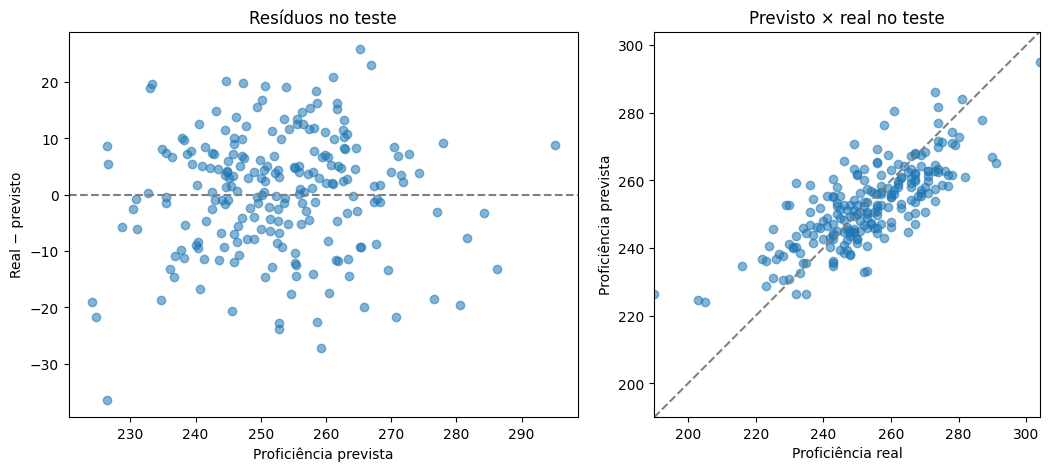

In [10]:
# ETAPA 21C — Avaliação do stacking selecionado nas turmas de teste
previsto = stacking.predict(X_test)
real = y_test.to_numpy()
residuos = real - previsto
r2_treino = busca_stacking.cv_results_["mean_train_score"][busca_stacking.best_index_]
r2_validacao = busca_stacking.best_score_

metricas = pd.DataFrame([{
    "R² treino (CV)": r2_treino,
    "R² validação (CV)": r2_validacao,
    "Gap": r2_treino - r2_validacao,
    "R² teste": r2_score(real, previsto),
    "MAE": mean_absolute_error(real, previsto),
    "RMSE": np.sqrt(mean_squared_error(real, previsto)),
    "MAPE (%)": 100 * np.mean(np.abs(residuos / real)) if np.all(real != 0) else np.nan,
}])
print(metricas.round(4).to_string(index=False))

n_pca = stacking.named_steps['pre'].named_steps['pca'].n_components_
nomes_meta = [nome for nome, _ in meta.estimators] + [f'pca{i} (passthrough)' for i in range(n_pca)]
print(f'PREPROC: {stacking.named_steps["pre"].named_steps["poly"].n_output_features_} atributos polinomiais → '
      f'{n_pca} componentes do PCA')
print(pd.Series(meta.final_estimator_.coef_, index=nomes_meta, name="Coeficientes do Ridge").round(4))

fig, (ax_res, ax_prev) = plt.subplots(1, 2, figsize=(11, 4.6), layout="constrained")
ax_res.scatter(previsto, residuos, alpha=0.55)
ax_res.axhline(0, linestyle="--", color="gray")
ax_res.set(title="Resíduos no teste", xlabel="Proficiência prevista", ylabel="Real − previsto")
limites = [min(real.min(), previsto.min()), max(real.max(), previsto.max())]
ax_prev.scatter(real, previsto, alpha=0.55)
ax_prev.plot(limites, limites, "--", color="gray")
ax_prev.set(
    title="Previsto × real no teste", xlabel="Proficiência real", ylabel="Proficiência prevista",
    xlim=limites, ylim=limites, aspect="equal",
)
plt.show()

### Diagnósticos da regressão linear (Etapas 04 e 05)

Os diagnósticos com as turmas de teste são executados após a seleção do stacking.

In [11]:
#ETAPA04
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.metrics import r2_score



# Regressão Linear
lr = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)

rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr  = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)
mape_lr = (np.abs((y_test - y_pred_lr) / y_test)).mean() * 100

print(f'LinearRegression → R²={r2_lr:.3f}, MAE={mae_lr:.2f}, RMSE={rmse_lr:.2f}, MAPE={mape_lr:.2f}%')


LinearRegression → R²=0.529, MAE=8.82, RMSE=11.20, MAPE=3.54%


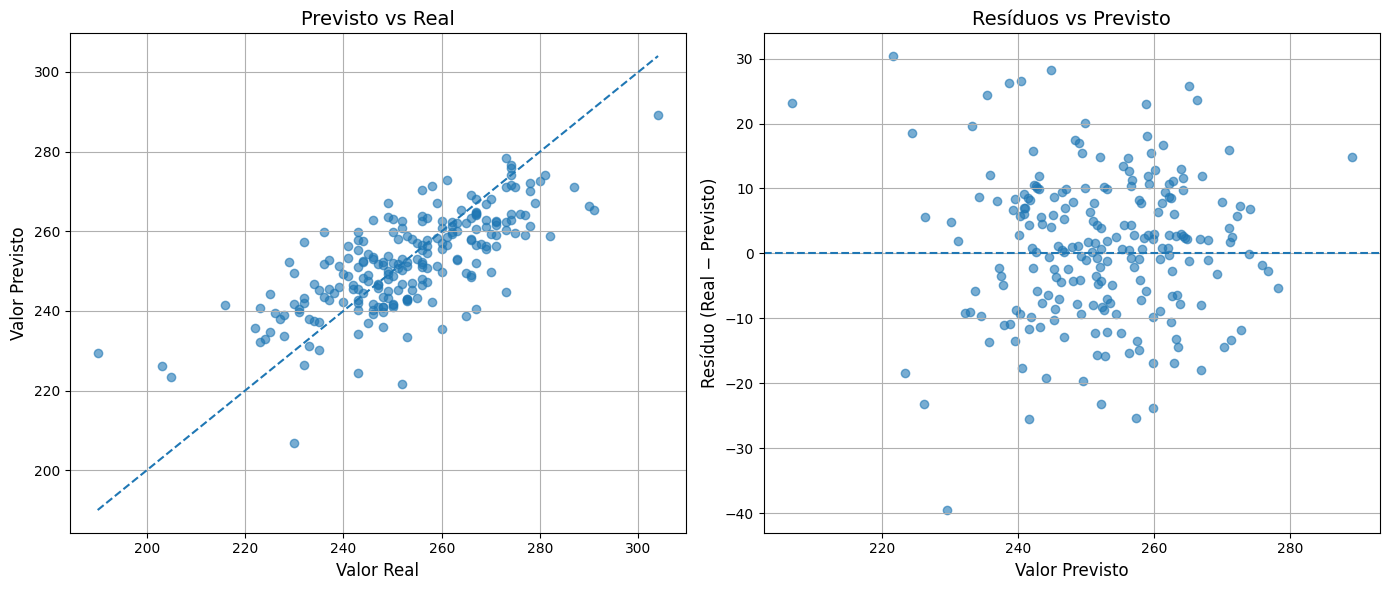

In [12]:
#ETAPA 05
import matplotlib.pyplot as plt

#Configura os subplots lado a lado
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
residuals = y_test - y_pred_lr
# --- Gráfico 1: Previsto vs Real ---
ax = axes[0]
ax.scatter(y_test, y_pred_lr, alpha=0.6)
ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle='--')
ax.set_xlabel('Valor Real', fontsize=12)
ax.set_ylabel('Valor Previsto', fontsize=12)
ax.set_title('Previsto vs Real', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

# --- Gráfico 2: Resíduos vs Previsto ---
ax = axes[1]
ax.scatter(y_pred_lr, residuals, alpha=0.6)
ax.axhline(0, linestyle='--')
ax.set_xlabel('Valor Previsto', fontsize=12)
ax.set_ylabel('Resíduo (Real − Previsto)', fontsize=12)
ax.set_title('Resíduos vs Previsto', fontsize=14)
ax.grid(True)
ax.tick_params(axis='both', which='major', labelsize=10)

plt.tight_layout()
plt.show()


▶ Regressão Linear
▶ MLP Regressor
▶ Random Forest
▶ XGBoost
▶ CatBoost


,R² treino (CV),R² validação (CV),Gap treino–validação,R² teste,MAE,RMSE,MAPE (%)
Modelo,,,,,,,
Stacking (RF + XGBoost + CatBoost + SVR → Ridge),0.5571,0.4961,0.0609,0.5843,8.3926,10.5167,3.3571
MLP Regressor,0.5119,0.4571,0.0548,0.5742,8.4083,10.6444,3.3691
CatBoost,0.6693,0.4737,0.1956,0.5547,8.6493,10.8851,3.4587
Random Forest,0.8144,0.4455,0.3688,0.5484,8.7740,10.9624,3.5134
XGBoost,0.6921,0.4595,0.2326,0.5433,8.8375,11.0236,3.5379
Regressão Linear,0.4764,0.4547,0.0217,0.5378,8.7572,11.0893,3.5109


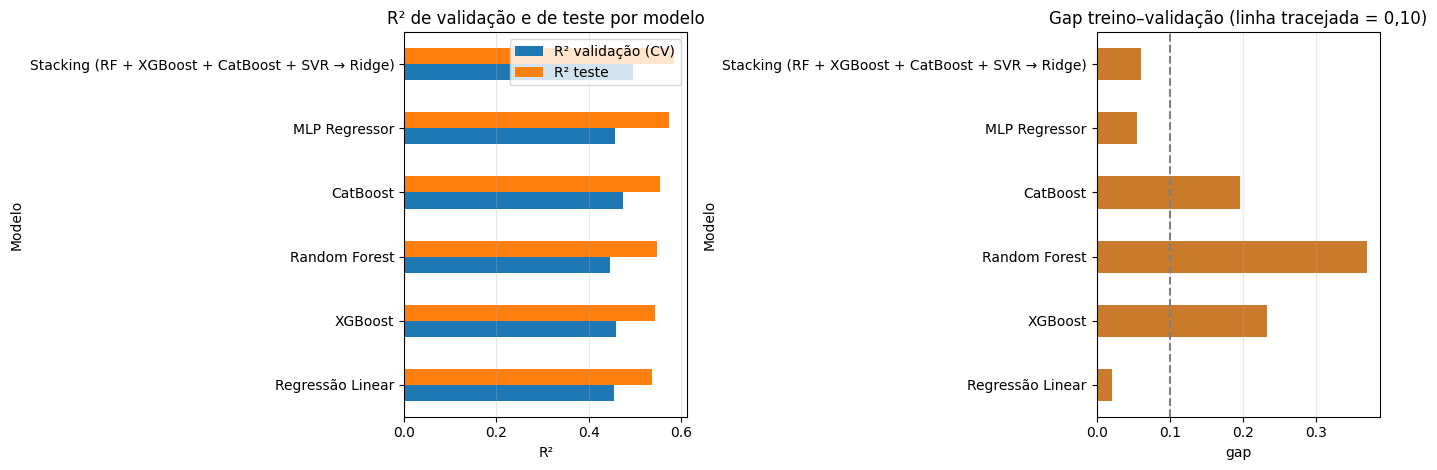

In [13]:
# ETAPA 22 — Comparativo do stacking com os algoritmos da dissertação
# Mesmo protocolo para todos (seção 4.5): o mesmo PREPROC na frente de cada modelo, treino com as 515 turmas,
# validação cruzada K-Fold (k = 5, embaralhada, seed 42) para R² treino, R² validação e gap,
# e avaliação final nas 221 turmas de teste. Hiperparâmetros por RandomizedSearchCV (20 combinações) só no treino.
# Usa criar_preproc e metricas das ETAPAS 21A e 21C.
from sklearn.model_selection import cross_validate
from sklearn.linear_model import LinearRegression
from sklearn.neural_network import MLPRegressor
import warnings
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', message='k=20 is greater than n_features')

kf = KFold(n_splits=5, shuffle=True, random_state=SEED)

def avaliar(nome, modelo):
    cv = cross_validate(modelo, X_train, y_train, cv=kf, scoring='r2', return_train_score=True, n_jobs=1)
    tr, va = cv['train_score'].mean(), cv['test_score'].mean()
    p = modelo.fit(X_train, y_train).predict(X_test)
    return {'Modelo': nome, 'R² treino (CV)': tr, 'R² validação (CV)': va, 'Gap treino–validação': tr - va,
            'R² teste': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p),
            'RMSE': np.sqrt(mean_squared_error(y_test, p)), 'MAPE (%)': np.mean(np.abs((y_test - p) / y_test)) * 100}

def pp(m):   # o mesmo PREPROC do stacking na frente de cada modelo
    return Pipeline([('pre', criar_preproc()), ('model', m)])

def busca(est, grade):   # RandomizedSearchCV com 20 combinações, escolhidas pelo R² de validação cruzada
    return RandomizedSearchCV(est, grade, n_iter=20, cv=kf, scoring='r2', n_jobs=1,
                              random_state=SEED).fit(X_train, y_train).best_estimator_

modelos = {
    'Regressão Linear': pp(LinearRegression()),
    'MLP Regressor': busca(pp(MLPRegressor(random_state=SEED, max_iter=2000)),
        {'model__hidden_layer_sizes': [(50,), (100,), (50, 50)], 'model__activation': ['relu', 'tanh'],
         'model__alpha': [1e-4, 1e-3, 1e-2], 'model__learning_rate_init': [.001, .01]}),
    'Random Forest': busca(pp(RandomForestRegressor(random_state=SEED)),
        {'model__n_estimators': [200, 400, 800], 'model__max_depth': [5, 10, 15],
         'model__min_samples_leaf': [2, 5, 10], 'model__max_features': ['sqrt', .5]}),
    'XGBoost': busca(pp(XGBRegressor(objective='reg:squarederror', random_state=SEED, n_jobs=1)),
        {'model__n_estimators': [200, 400, 800], 'model__max_depth': [3, 4, 5], 'model__learning_rate': [.01, .05, .1],
         'model__subsample': [.6, .8, 1.], 'model__colsample_bytree': [.6, .8, 1.],
         'model__reg_alpha': [0, .1, 1], 'model__reg_lambda': [1, 5, 10]}),
    'CatBoost': busca(pp(CatBoostRegressor(verbose=0, thread_count=1, random_state=SEED, allow_writing_files=False)),
        {'model__iterations': [200, 400, 800], 'model__depth': [4, 6, 8], 'model__learning_rate': [.01, .05, .1],
         'model__l2_leaf_reg': [1, 3, 5], 'model__subsample': [.6, .8, 1.], 'model__rsm': [.6, .8, 1.]}),
}
linhas = []
for nome, m in modelos.items():
    print('▶', nome); linhas.append(avaliar(nome, m))
NOME_STACK = 'Stacking (RF + XGBoost + CatBoost + SVR → Ridge)'
linhas.append({'Modelo': NOME_STACK, **metricas.rename(columns={'Gap': 'Gap treino–validação'}).iloc[0].to_dict()})   # ETAPA 21C

comparativo = pd.DataFrame(linhas).set_index('Modelo').sort_values('R² teste', ascending=False)
display(comparativo.round(4))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
c = comparativo.iloc[::-1]
c[['R² validação (CV)', 'R² teste']].plot.barh(ax=ax[0])
ax[0].set(title='R² de validação e de teste por modelo', xlabel='R²')
c['Gap treino–validação'].plot.barh(ax=ax[1], color='#c97a2b'); ax[1].axvline(0.10, ls='--', color='gray')
ax[1].set(title='Gap treino–validação (linha tracejada = 0,10)', xlabel='gap')
for a in ax: a.grid(axis='x', alpha=.3)
plt.tight_layout(); plt.show()

,|SHAP| médio (pontos de proficiência),IC 95% inferior,IC 95% superior,SHAP mínimo,SHAP máximo,Peso relativo (%)
INTERMEDIARIO,5.513,4.978,6.032,-13.059,18.958,49.313
INICIAL,3.130,2.825,3.453,-8.905,13.589,28.000
FINAL,2.536,2.255,2.831,-8.468,11.537,22.687


,Diferença média de |SHAP|,p-valor (Wilcoxon pareado),"Significativo (α = 0,05)?"
Comparação,,,
INTERMEDIARIO × INICIAL,2.383,4.815578e-16,sim
INTERMEDIARIO × FINAL,2.977,2.811158e-21,sim


Avaliação de maior peso na proficiência prevista: INTERMEDIARIO (49.3% do total de SHAP)


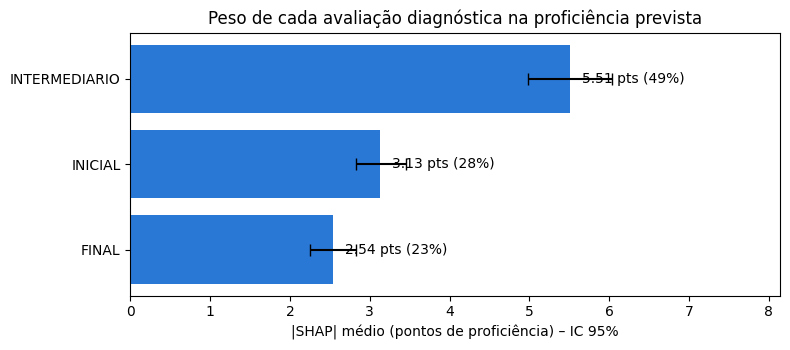

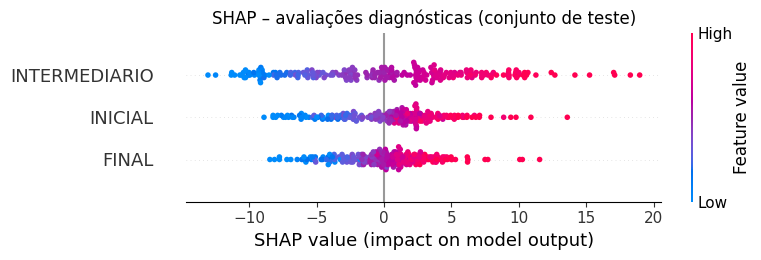

In [14]:
# ETAPA 23 — SHAP: peso de cada avaliação (INICIAL, INTERMEDIÁRIA, FINAL) na proficiência prevista
# KernelExplainer sobre o stacking completo: o valor SHAP diz quantos pontos de proficiência cada avaliação
# acrescenta ou retira da previsão de cada turma do teste, em relação à previsão média.
import shap
from scipy import stats

fundo = X_train.sample(100, random_state=SEED)                    # amostra de referência
prever = lambda Z: stacking.predict(pd.DataFrame(Z, columns=ENTRADAS))   # mantém os nomes das colunas
explicador = shap.KernelExplainer(prever, fundo)
shap_aval = explicador.shap_values(X_test, silent=True)           # matriz 221 turmas × 3 avaliações
abs_shap = pd.DataFrame(np.abs(shap_aval), columns=ENTRADAS, index=X_test.index)

# Quantidade de SHAP por avaliação, com IC 95% por bootstrap
rng = np.random.default_rng(SEED)
boot = np.array([abs_shap.iloc[rng.integers(0, len(abs_shap), len(abs_shap))].mean().values for _ in range(2000)])
peso = pd.DataFrame({'|SHAP| médio (pontos de proficiência)': abs_shap.mean(),
                     'IC 95% inferior': np.percentile(boot, 2.5, axis=0),
                     'IC 95% superior': np.percentile(boot, 97.5, axis=0),
                     'SHAP mínimo': shap_aval.min(0), 'SHAP máximo': shap_aval.max(0)}, index=ENTRADAS)
peso['Peso relativo (%)'] = 100 * peso.iloc[:, 0] / peso.iloc[:, 0].sum()
peso = peso.sort_values('|SHAP| médio (pontos de proficiência)', ascending=False)
display(peso.round(3))

# Prova estatística: a avaliação de maior peso tem |SHAP| maior que as outras? (Wilcoxon pareado, turma a turma)
maior = peso.index[0]
testes = pd.DataFrame([{'Comparação': f'{maior} × {v}',
                        'Diferença média de |SHAP|': (abs_shap[maior] - abs_shap[v]).mean(),
                        'p-valor (Wilcoxon pareado)': stats.wilcoxon(abs_shap[maior], abs_shap[v]).pvalue}
                       for v in peso.index[1:]]).set_index('Comparação')
testes['Significativo (α = 0,05)?'] = np.where(testes['p-valor (Wilcoxon pareado)'] < .05, 'sim', 'não')
display(testes.round({'Diferença média de |SHAP|': 3}))
print(f'Avaliação de maior peso na proficiência prevista: {maior} '
      f'({peso.loc[maior, "Peso relativo (%)"]:.1f}% do total de SHAP)')

# Gráficos: barras com a quantidade de SHAP e enxame (beeswarm)
fig, ax = plt.subplots(figsize=(8, 3.6))
y_pos = np.arange(len(peso))[::-1]
ax.barh(y_pos, peso.iloc[:, 0], xerr=[peso.iloc[:, 0] - peso['IC 95% inferior'], peso['IC 95% superior'] - peso.iloc[:, 0]],
        capsize=4, color='#2a78d6')
for yy, v, pct in zip(y_pos, peso.iloc[:, 0], peso['Peso relativo (%)']):
    ax.text(v + .15, yy, f'{v:.2f} pts ({pct:.0f}%)', va='center')
ax.set_yticks(y_pos, peso.index); ax.set_xlabel('|SHAP| médio (pontos de proficiência) – IC 95%')
ax.set_title('Peso de cada avaliação diagnóstica na proficiência prevista'); ax.set_xlim(0, peso['IC 95% superior'].max() * 1.35)
plt.tight_layout(); plt.show()

shap.summary_plot(shap_aval, X_test, show=False)
plt.title('SHAP – avaliações diagnósticas (conjunto de teste)'); plt.tight_layout(); plt.show()


,Peso no Ridge (coeficiente),|SHAP| médio (pontos de proficiência),Participação no SHAP (%),Tipo
SVR,0.7042,6.6631,33.7926,modelo-base
pca0 (passthrough),8.2350,6.5695,33.3179,componente do PREPROC (passthrough)
pca1 (passthrough),2.4785,1.9144,9.7092,componente do PREPROC (passthrough)
Random Forest,-0.2084,1.7457,8.8535,modelo-base
CatBoost,-0.1680,1.4400,7.3029,modelo-base
XGBoost,-0.1197,0.8887,4.5072,modelo-base
pca2 (passthrough),0.6601,0.4962,2.5166,componente do PREPROC (passthrough)


Participação dos modelos-base no SHAP do meta-modelo: 54.5% | componentes (passthrough): 45.5%
Correlação entre as previsões out-of-fold dos modelos-base:


,Random Forest,XGBoost,CatBoost,SVR
Random Forest,1.000,0.989,0.990,0.910
XGBoost,0.989,1.000,0.988,0.919
CatBoost,0.990,0.988,1.000,0.928
SVR,0.910,0.919,0.928,1.000


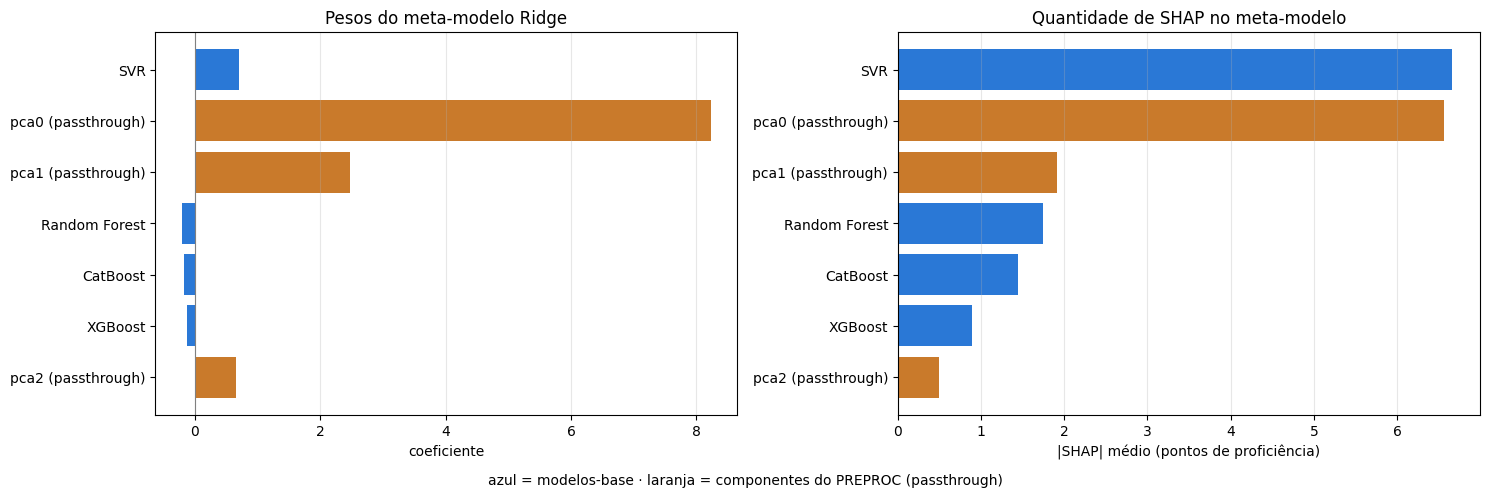

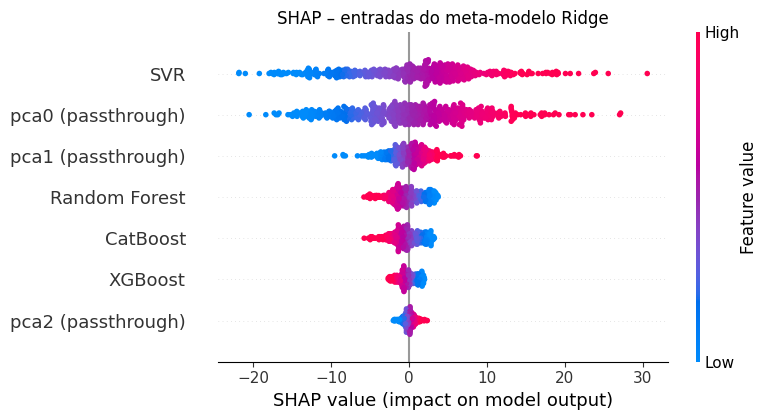

In [15]:
# ETAPA 24 — SHAP do meta-modelo: peso de cada algoritmo do stacking
# O meta-modelo Ridge recebe as previsões dos 4 modelos-base e, com passthrough=True, também as componentes do PREPROC.
# As previsões usadas aqui são out-of-fold (as mesmas que treinaram o meta-modelo: KFold(5) interno do StackingRegressor).
from sklearn.model_selection import cross_val_predict
X_pre = pd.DataFrame(stacking.named_steps['pre'].transform(X_train), index=X_train.index,
                     columns=[f'pca{i} (passthrough)' for i in range(n_pca)])
oof = pd.DataFrame({n: cross_val_predict(clone(m), X_pre.values, y_train, cv=KFold(n_splits=5))
                    for n, m in meta.estimators}, index=X_train.index)
X_meta = pd.concat([oof, X_pre], axis=1)

explicador_meta = shap.KernelExplainer(meta.final_estimator_.predict, X_meta.sample(100, random_state=SEED).values)
shap_meta = explicador_meta.shap_values(X_meta.values, silent=True)

pesos = pd.DataFrame({'Peso no Ridge (coeficiente)': meta.final_estimator_.coef_,
                      '|SHAP| médio (pontos de proficiência)': np.abs(shap_meta).mean(0)}, index=X_meta.columns)
pesos['Participação no SHAP (%)'] = 100 * pesos.iloc[:, 1] / pesos.iloc[:, 1].sum()
pesos['Tipo'] = ['modelo-base'] * len(meta.estimators) + ['componente do PREPROC (passthrough)'] * n_pca
pesos = pesos.sort_values('|SHAP| médio (pontos de proficiência)', ascending=False)
display(pesos.round(4))
print('Participação dos modelos-base no SHAP do meta-modelo: '
      f'{pesos.loc[pesos.Tipo == "modelo-base", "Participação no SHAP (%)"].sum():.1f}% | '
      f'componentes (passthrough): {pesos.loc[pesos.Tipo != "modelo-base", "Participação no SHAP (%)"].sum():.1f}%')
print('Correlação entre as previsões out-of-fold dos modelos-base:')
display(oof.corr().round(3))

fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
pp_ = pesos.iloc[::-1]
cores = ['#2a78d6' if t == 'modelo-base' else '#c97a2b' for t in pp_.Tipo]
ax[0].barh(pp_.index, pp_['Peso no Ridge (coeficiente)'], color=cores); ax[0].axvline(0, color='gray', lw=.8)
ax[0].set(title='Pesos do meta-modelo Ridge', xlabel='coeficiente')
ax[1].barh(pp_.index, pp_['|SHAP| médio (pontos de proficiência)'], color=cores)
ax[1].set(title='Quantidade de SHAP no meta-modelo', xlabel='|SHAP| médio (pontos de proficiência)')
for a in ax: a.grid(axis='x', alpha=.3)
fig.text(.5, -.02, 'azul = modelos-base · laranja = componentes do PREPROC (passthrough)', ha='center')
plt.tight_layout(); plt.show()

shap.summary_plot(shap_meta, X_meta, show=False)
plt.title('SHAP – entradas do meta-modelo Ridge'); plt.tight_layout(); plt.show()

Estatísticas do ganho previsto de proficiência (uplift) – 55%–60% na INTERMEDIÁRIA, +10 p.p.


,Valor
Número de turmas (n),47
Média,8.007
Mediana,8.139
Desvio padrão (DP),3.648
Mínimo,-0.406
1º Quartil (Q1),5.526
3º Quartil (Q3),9.992
Máximo,18.545
IC 95% da média,[6.936 ; 9.078]
IC 95% da mediana (bootstrap),[6.297 ; 9.041]


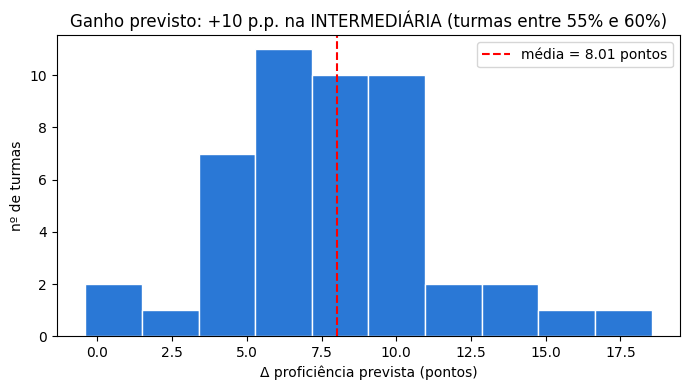

,INICIAL,INTERMEDIARIO,FINAL,Proficiência prevista,Δ previsto (+10 p.p.)
356,66,57,52,242.91,18.55
33,67,60,63,248.31,15.68
296,66,58,63,245.92,14.38
473,69,58,65,245.94,13.54
139,67,58,65,247.21,12.83
66,48,60,69,244.52,11.90
344,60,56,59,244.33,10.91
583,45,59,55,236.84,10.78
259,64,60,67,251.74,10.66
631,55,59,70,247.87,10.61


,Número de turmas (n),Média,Mediana,Desvio padrão (DP),IC 95% da média,IC 95% da mediana (bootstrap)
INICIAL,53,1.894,1.103,4.873,[0.551 ; 3.238],[-0.789 ; 3.242]
INTERMEDIARIO,47,8.007,8.139,3.648,[6.936 ; 9.078],[6.297 ; 9.041]
FINAL,38,3.066,2.140,3.210,[2.011 ; 4.121],[1.401 ; 3.636]


In [16]:
# ETAPA 25 — Simulação contrafactual: +10 p.p. na avaliação INTERMEDIÁRIA (turmas entre 55% e 60%)
# Algoritmo 2 da dissertação, no conjunto de teste. INICIAL e FINAL ficam constantes.
# Δ = ŷ_novo − ŷ_original é o ganho que o MODELO prevê; não é o efeito causal de uma intervenção pedagógica.
def contrafactual(var='INTERMEDIARIO', faixa=(55, 60), incremento=10, B=5000):
    S = X_test[(X_test[var] >= faixa[0]) & (X_test[var] <= faixa[1])]
    if len(S) == 0:
        return None, None
    S_novo = S.copy(); S_novo[var] = np.minimum(100, S_novo[var] + incremento)
    delta = pd.Series(stacking.predict(S_novo) - stacking.predict(S), index=S.index)
    n, media, dp = len(delta), delta.mean(), delta.std(ddof=1)
    ic_media = stats.t.interval(.95, n - 1, loc=media, scale=dp / np.sqrt(n))
    rng = np.random.default_rng(SEED)
    ic_mediana = np.percentile([np.median(rng.choice(delta.values, n, replace=True)) for _ in range(B)], [2.5, 97.5])
    resumo = pd.Series({'Número de turmas (n)': n, 'Média': media, 'Mediana': delta.median(), 'Desvio padrão (DP)': dp,
                        'Mínimo': delta.min(), '1º Quartil (Q1)': delta.quantile(.25), '3º Quartil (Q3)': delta.quantile(.75),
                        'Máximo': delta.max(),
                        'IC 95% da média': f'[{ic_media[0]:.3f} ; {ic_media[1]:.3f}]',
                        'IC 95% da mediana (bootstrap)': f'[{ic_mediana[0]:.3f} ; {ic_mediana[1]:.3f}]'})
    return resumo, delta

fmt = lambda v: f'{v:.3f}' if isinstance(v, float) else v
resumo, delta = contrafactual('INTERMEDIARIO')
print('Estatísticas do ganho previsto de proficiência (uplift) – 55%–60% na INTERMEDIÁRIA, +10 p.p.')
display(resumo.map(fmt).to_frame('Valor'))

plt.figure(figsize=(7, 4)); plt.hist(delta, bins=10, edgecolor='white', color='#2a78d6')
plt.axvline(delta.mean(), color='red', ls='--', label=f'média = {delta.mean():.2f} pontos')
plt.xlabel('Δ proficiência prevista (pontos)'); plt.ylabel('nº de turmas')
plt.title('Ganho previsto: +10 p.p. na INTERMEDIÁRIA (turmas entre 55% e 60%)'); plt.legend()
plt.tight_layout(); plt.show()

detalhe = X_test.loc[delta.index].assign(**{'Proficiência prevista': stacking.predict(X_test.loc[delta.index]),
                                             'Δ previsto (+10 p.p.)': delta})
display(detalhe.sort_values('Δ previsto (+10 p.p.)', ascending=False).round(2))

# Mesmo exercício em cada avaliação, para comparar onde o ganho previsto é maior
comparacao = pd.DataFrame({v: contrafactual(v)[0] for v in ENTRADAS}).T
display(comparacao[['Número de turmas (n)', 'Média', 'Mediana', 'Desvio padrão (DP)',
                    'IC 95% da média', 'IC 95% da mediana (bootstrap)']].map(fmt))


In [17]:
# ETAPA 26 — Auditoria automática do código
# Cada verificação imprime OK ou FALHA. Nenhuma delas usa o teste para escolher nada.
import inspect
from sklearn.model_selection import cross_val_predict
aud = []
def check(nome, cond, detalhe=''):
    aud.append({'Verificação': nome, 'Resultado': 'OK' if cond else 'FALHA', 'Detalhe': detalhe})

# 1. Divisão e vazamento
check('Treino e teste sem turmas em comum', X_train.index.intersection(X_test.index).empty,
      f'{len(X_train)} treino / {len(X_test)} teste')
check('Divisão 70/30 reproduzível (seed 42)',
      train_test_split(X, y, test_size=0.3, random_state=42)[1].index.equals(X_test.index))
check('Coluna DESEMPENHO fora das entradas', 'DESEMPENHO' not in X_train.columns, f'entradas: {list(X_train.columns)}')
check('Busca do alpha ajustada só com o treino', busca_stacking.n_splits_ == 5 and
      len(busca_stacking.cv_results_['mean_test_score']) == 4, 'RandomizedSearchCV(cv=KFold 5) em X_train')

# 2. O PREPROC é ajustado dentro de cada dobra (está dentro do Pipeline do modelo)
check('PREPROC dentro do Pipeline do stacking', list(stacking.named_steps)[0] == 'pre')
check('PREPROC dentro do Pipeline de cada modelo comparado', all(list(m.named_steps)[0] == 'pre' for m in modelos.values()))

# 3. Métricas recalculadas de forma independente
p = stacking.predict(X_test)
check('R² de teste confere', np.isclose(r2_score(y_test, p), metricas['R² teste'][0]), f"{r2_score(y_test, p):.4f}")
r2_manual = 1 - ((y_test - p) ** 2).sum() / ((y_test - y_test.mean()) ** 2).sum()
check('R² de teste confere pela fórmula 1 − SQres/SQtot', np.isclose(r2_manual, metricas['R² teste'][0]), f'{r2_manual:.4f}')
check('MAE, RMSE e MAPE conferem', np.allclose([np.mean(np.abs(y_test - p)), np.sqrt(np.mean((y_test - p) ** 2)),
                                                100 * np.mean(np.abs((y_test - p) / y_test))],
                                               metricas[['MAE', 'RMSE', 'MAPE (%)']].values[0]))

# 4. Reprodutibilidade: reajustar do zero dá a mesma previsão
p2 = criar_stacking(alpha=meta.final_estimator_.alpha).fit(X_train, y_train).predict(X_test)
check('Reajuste do zero reproduz as previsões', np.allclose(p, p2, atol=1e-6), f'diferença máx. {np.abs(p - p2).max():.2e}')

# 5. Validação cruzada recalculada fora do RandomizedSearchCV
cv2 = cross_validate(criar_stacking(alpha=meta.final_estimator_.alpha), X_train, y_train, cv=kf, scoring='r2',
                     return_train_score=True)
check('R² treino e validação (CV) conferem', np.isclose(cv2['test_score'].mean(), r2_validacao) and
      np.isclose(cv2['train_score'].mean(), r2_treino), f"val {cv2['test_score'].mean():.4f}")
check('Gap treino–validação ≤ 0,10', metricas['Gap'][0] <= 0.10, f"{metricas['Gap'][0]:.4f}")

# 6. SHAP: a soma dos valores SHAP + valor esperado reproduz a previsão (propriedade de aditividade)
adit = np.abs(np.asarray(explicador.expected_value) + shap_aval.sum(1) - stacking.predict(X_test)).max()
check('SHAP das avaliações é aditivo', adit < 1e-3, f'erro máx. {adit:.2e}')
adit_m = np.abs(np.asarray(explicador_meta.expected_value) + shap_meta.sum(1) - meta.final_estimator_.predict(X_meta.values)).max()
check('SHAP do meta-modelo é aditivo', adit_m < 1e-3, f'erro máx. {adit_m:.2e}')
meta_rep = Ridge(alpha=meta.final_estimator_.alpha).fit(X_meta.values, y_train)
check('Entradas OOF da ETAPA 24 reproduzem o meta-modelo treinado', np.allclose(meta_rep.coef_, meta.final_estimator_.coef_, atol=1e-6),
      f'diferença máx. dos coeficientes {np.abs(meta_rep.coef_ - meta.final_estimator_.coef_).max():.2e}')

# 7. Contrafactual: só a INTERMEDIÁRIA muda e as previsões são da faixa 55–60%
S = X_test[(X_test.INTERMEDIARIO >= 55) & (X_test.INTERMEDIARIO <= 60)]
check('Contrafactual usa só turmas do teste entre 55% e 60%', set(delta.index) == set(S.index), f'n = {len(S)}')
S1 = S.copy(); S1['INTERMEDIARIO'] = np.minimum(100, S1['INTERMEDIARIO'] + 10)
check('Δ do contrafactual reproduzido', np.allclose(stacking.predict(S1) - stacking.predict(S), delta.values),
      f'média {delta.mean():.3f}')

# 8. Zou (2007): conferir a fórmula com um caso calculado à mão
l1, u1 = ic_fisher(0.608, 515); l2, u2 = ic_fisher(0.645, 481)
check('Fórmula de Zou coerente com os IC de Fisher', np.isclose(zou_2007(0.608, 515, 0.645, 481)[0],
      (0.645 - 0.608) - np.sqrt((0.645 - l2) ** 2 + (u1 - 0.608) ** 2)))

auditoria = pd.DataFrame(aud)
display(auditoria)
print(f"{(auditoria.Resultado == 'OK').sum()} de {len(auditoria)} verificações OK")

,Verificação,Resultado,Detalhe
0,Treino e teste sem turmas em comum,OK,515 treino / 221 teste
1,Divisão 70/30 reproduzível (seed 42),OK,
2,Coluna DESEMPENHO fora das entradas,OK,"entradas: ['INICIAL', 'INTERMEDIARIO', 'FINAL']"
3,Busca do alpha ajustada só com o treino,OK,RandomizedSearchCV(cv=KFold 5) em X_train
4,PREPROC dentro do Pipeline do stacking,OK,
5,PREPROC dentro do Pipeline de cada modelo comp...,OK,
6,R² de teste confere,OK,0.5843
7,R² de teste confere pela fórmula 1 − SQres/SQtot,OK,0.5843
8,"MAE, RMSE e MAPE conferem",OK,
9,Reajuste do zero reproduz as previsões,OK,diferença máx. 0.00e+00


18 de 18 verificações OK
